# Phase 1: Autoregressive models.

•Implement and train a simple MLP language model akin to Figure 1 in [2] that takes in the
three previous tokens (amino acids) and predicts the next, using a deep learning framework
such as PyTorch. The model architecture and hyperparameters are up to you, but clearly state
and justify your choices in the report.


•Implement and train a recurrent neural network (RNN) model or a causal decoder-only multi-
head attention Transformer model [3]. For the RNN choose between the vanilla RNN, Gated
Recurrent Unit (GRU) or Long Short-Term Memory (LSTM). Like the MLP, the specific model
design is up to you but needs to be explained and justified in the report.


•Evaluate and visualize the performance of these models by folding the generated sequences
with ESMFold [4] and presenting relevant metrics (code for evaluation will be provided).

---

## Importing the data

In [101]:
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [102]:
#device = torch.device(
#    "mps" if torch.backends.mps.is_available() else "cpu"
#)
#print("Using:", device)

In [ ]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

## Defining the transformer

### Iniatiing embedings

For the embeddings we are intializing a trainable lookup table 

Num_embeddings is the vocab size 

Embeding dim, is an arbitary number we define, we define it as 128. But if our model is to weak, we can go back and increase it. 

It works by applying the embeding to each element in an input 

\<BOS>, A, C, \<EOS>, \<PAD>

x = torch.tensor([[1, 3, 4, 2, 0]])  # Shape: [1, 5]

embedded_x = token_embedding(x)     # Shape: [1, 5, 128]

In [104]:
token_embedding = nn.Embedding(
    num_embeddings=train_data.vocab_size,
    embedding_dim=128,
    padding_idx=train_data.vocab["<PAD>"], # PyTorch initializes that embedding row to zeros and excludes it from embedding-gradient updates
)

We now add positional embedings and combine them with our token embeding 

In [105]:
position_embedding = nn.Embedding(
    num_embeddings=train_data.max_length,
    embedding_dim=128,
)

# Run it on one batch to check the shapes
x, targets, family, lengths = next(iter(train_loader))


positions = torch.arange(x.size(1), device=x.device)
h = token_embedding(x) + position_embedding(positions)

print("Input shape:", x.shape)       # [32, 129]
print("Embedding shape:", h.shape)   # [32, 129, 128]

Input shape: torch.Size([32, 129])
Embedding shape: torch.Size([32, 129, 128])


### Building the casual mask 

For the Mask we want Query to be able to see the Key for its own position and the ones before it 

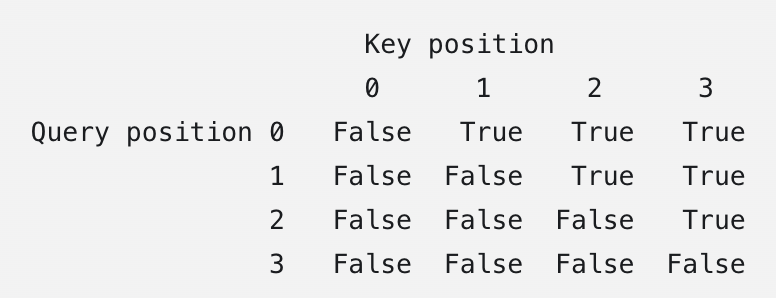

Torch ones, creates the matrix 129 x 129, and triu(ONES, diagonal=1) takes the matrix just created and sets points only over the diagonal to True. True in this case means that they are marked for blocking

In [106]:
T = x.size(1)
causal_mask = torch.triu( 
    torch.ones(T, T, dtype=torch.bool, device=x.device), 
    diagonal=1,
)

print(T)

129


### Building one transformer block

Here we introduce Multih head attention. Each head computes its own attention weights and their outputs are concatenated and projected back to 128 dimensions.

In [107]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model=128, n_heads=4, d_ff=512, dropout=0.1):
        super().__init__()

        # Normalization and creating heads
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

        # Drops 10% of the residual connection
        self.residual_dropout = nn.Dropout(dropout)

    def forward(self, h, causal_mask, padding_mask):
        # Attention sublayer
        normalized = self.norm1(h)
        attended, _ = self.attention(
            normalized,
            normalized,
            normalized,
            attn_mask=causal_mask,
            key_padding_mask=padding_mask,
            need_weights=False,
        )
        h = h + self.residual_dropout(attended)

        # Feed-forward sublayer
        h = h + self.residual_dropout(
            self.feed_forward(self.norm2(h))
        )
        return h

### Stacking the blocks to create the transformer

In [108]:
class CausalProteinTransformer(nn.Module):
    def __init__(
        self,
        vocab_size=23,
        max_length=129,
        d_model=128,
        n_heads=4,
        n_layers=4,
        d_ff=512,
        dropout=0.1,
        pad_id=0,
    ):
        super().__init__()
        self.pad_id = pad_id

        self.token_embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=pad_id
        )
        self.position_embedding = nn.Embedding(max_length, d_model)
        self.embedding_dropout = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        self.final_norm = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, 3) # Down to the 3 families


    def forward(self, x):
        _, T = x.shape

        positions = torch.arange(T, device=x.device)
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.embedding_dropout(h)

        causal_mask = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=x.device),
            diagonal=1,
        )
        padding_mask = x.eq(self.pad_id)

        for block in self.blocks:
            h = block(h, causal_mask, padding_mask)

        #return self.output(self.final_norm(h))
        return F.softmax(self.output(self.final_norm(h)), dim=2) # F.softmax(x, dim=2) # softmax to be performed on the third dimension


In [109]:
# One batch test

model = CausalProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    pad_id=train_data.vocab["<PAD>"],
)

x, targets, family, lengths = next(iter(train_loader))
logits = model(x)

print("Input:", x.shape)
print("Logits:", logits.shape)

family_repeat = torch.repeat_interleave(family, repeats=129, dim=-1) # Repeat the family value for all the subsections (129 (the length of the sequences))

loss = F.cross_entropy(
    logits.reshape(-1, 3), # 3 for the three families
    family_repeat.reshape(-1),
    ignore_index=-1,
)

print("Initial loss:", loss.item())

Input: torch.Size([32, 129])
Logits: torch.Size([32, 129, 3])
Initial loss: 1.1037126779556274


In [131]:
# def accuracy(ys, ts):
#     # making a one-hot encoded vector of correct (1) and incorrect (0) predictions
#     correct_prediction = torch.eq(torch.max(ys, 1)[1], ts) # tr_targets is the last value and there there is not an extra index dimension
#     # averaging the one-hot encoded vector
#     return torch.mean(correct_prediction.float())
# New accuracy function:
def accuracy(ys, ts):
    predictions = ys.argmax(dim=-1)
    if ts.ndim == ys.ndim:
        targets = ts.argmax(dim=-1)
    else:
        targets = ts
    return (predictions == targets).float().mean()

def onehot(t, num_classes):
    out = np.zeros((t.shape[0], num_classes))
    for row, col in enumerate(t):
        out[row, col] = 1
    return out

In [132]:
# PROPPER TRAIN:
model = CausalProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    pad_id=train_data.vocab["<PAD>"],
)

In [135]:
import torch.optim as optim

optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

Epoch 0, Train Cost: 1.101	Val Cost: 1.102	 Val acc: 0.346
Epoch 10, Train Cost: 1.097	Val Cost: 1.093	 Val acc: 0.369
Epoch 20, Train Cost: 1.090	Val Cost: 1.089	 Val acc: 0.388
Epoch 30, Train Cost: 1.082	Val Cost: 1.077	 Val acc: 0.413
Epoch 40, Train Cost: 1.075	Val Cost: 1.069	 Val acc: 0.436
Epoch 50, Train Cost: 1.066	Val Cost: 1.062	 Val acc: 0.454
Epoch 60, Train Cost: 1.059	Val Cost: 1.052	 Val acc: 0.473
Epoch 70, Train Cost: 1.048	Val Cost: 1.036	 Val acc: 0.507
Epoch 80, Train Cost: 1.043	Val Cost: 1.030	 Val acc: 0.515
Epoch 90, Train Cost: 1.023	Val Cost: 1.014	 Val acc: 0.545
Epoch 100, Train Cost: 1.009	Val Cost: 0.998	 Val acc: 0.560
Epoch 110, Train Cost: 0.976	Val Cost: 0.979	 Val acc: 0.587
Epoch 120, Train Cost: 0.952	Val Cost: 0.914	 Val acc: 0.678
Epoch 130, Train Cost: 0.937	Val Cost: 0.929	 Val acc: 0.637
Epoch 140, Train Cost: 0.918	Val Cost: 0.880	 Val acc: 0.706
Epoch 150, Train Cost: 0.877	Val Cost: 0.858	 Val acc: 0.717
Epoch 160, Train Cost: 0.883	Val Co

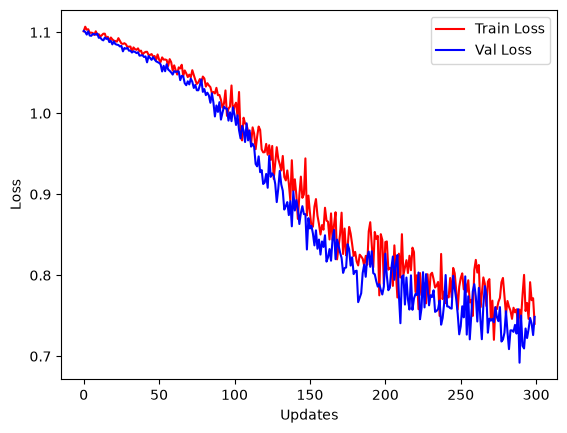

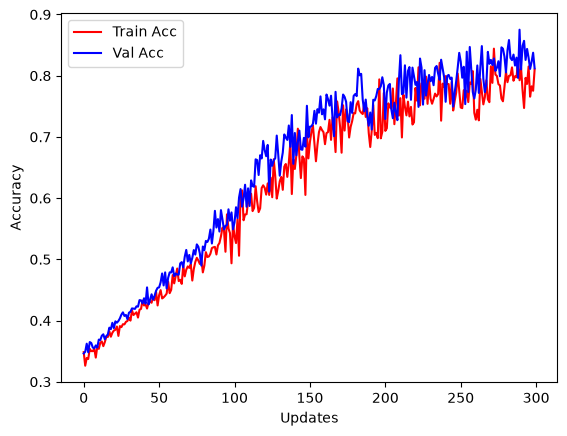

In [136]:
# number of training passses
batch_size_ = 32*2*2
train_loader = DataLoader(train_data, batch_size=batch_size_, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size_, shuffle=True)
size_of_traindata = len(train_data)
num_epochs = int(np.floor(size_of_traindata/batch_size_))
num_epochs = 300
#num_epochs = 
# store loss and accuracy for information
train_losses, val_losses, train_accs, val_accs = [], [], [], []
test_losses, test_accs = [], []

# training loop
for e in range(num_epochs):
    x, x_shifted, y, length = next(iter(train_loader))
    y_repeat = torch.repeat_interleave(y, repeats=129, dim=-1) # Repeat the family value for all the subsections (129 (the length of the sequences))
    # zeroize accumulated gradients in parameters
    optimizer.zero_grad()
    # predict by running forward pass
    tr_output = model(x)
    # compute cross entropy loss
    #tr_targetsOutput = net.embed(tr_targets)
    tr_loss = F.cross_entropy(
        tr_output.reshape(-1, 3), # 3 for the three families
        y_repeat.reshape(-1),
        ignore_index=-1,
    )
    # compute gradients given loss
    tr_loss.backward()
    # update the parameters given the computed gradients
    optimizer.step()
    train_acc = accuracy(tr_output.reshape(-1, 3), torch.tensor(onehot(y_repeat.reshape(-1),3)))
    
    # store training loss
    train_losses.append(tr_loss.data.numpy())
    train_accs.append(train_acc)

    # Validation:
    x, x_shifted, y, length = next(iter(val_loader))
    y_repeat = torch.repeat_interleave(y, repeats=129, dim=-1) # Repeat the family value for all the subsections (129 (the length of the sequences))
    val_output = model(x)
    val_loss = F.cross_entropy(
            val_output.reshape(-1, 3), # 3 for the three families
            y_repeat.reshape(-1),
            ignore_index=-1,
        )
    val_acc = accuracy(val_output.reshape(-1, 3), torch.tensor(onehot(y_repeat.reshape(-1),3)))

    val_losses.append(val_loss.data.numpy())
    val_accs.append(val_acc.data.numpy())
    
    if e % 10 == 0:
        print("Epoch %i, "
              "Train Cost: %0.3f"
              "\tVal Cost: %0.3f"
              "\t Val acc: %0.3f" % (e, 
                                     train_losses[-1],
                                     val_losses[-1],
                                     val_accs[-1]))
        
        
## get test input and expected output
#te_input = torch.from_numpy(X_te)
#te_targets = torch.from_numpy(onehot(y_te, num_output)).float()
## predict on testset
#te_output = net(te_input)
## compute loss and accuracy
#te_loss = cross_entropy(te_output, te_targets)
#te_acc = accuracy(te_output, te_targets)
#print("\nTest Cost: %0.3f\tTest Accuracy: %0.3f" % (te_loss.data.numpy(), te_acc.data.numpy()))

plt.figure()
epoch = np.arange(len(train_losses))
plt.plot(epoch, train_losses, 'r', label='Train Loss')
plt.plot(epoch, val_losses, 'b', label='Val Loss')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Loss')
plt.show()

plt.figure()
plt.plot(epoch, train_accs, 'r', label='Train Acc')
plt.plot(epoch, val_accs, 'b', label='Val Acc')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Accuracy')
plt.show()

In [137]:
torch.save(model.state_dict(), 'classifierModel.pt')

# model = TheModelClass(*args, **kwargs)
# model.load_state_dict(torch.load(PATH, weights_only=True))
# model.eval()